# code_218 · Measure the whole inference path with an actual frozen foundation model

**Book:** section 41.3. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials and one explicitly acquired cached checkpoint. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_41_GUIDE.md), [execution evidence](../CHAPTER_41_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_218).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Deployment contracts bind source-fitted transformations, model state, schema and version. Resource measurements are actual observations of this run, separated from deterministic scientific results; no production service or autonomous engineering clearance is claimed. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or new asset is added; the pinned Chapter35 checkpoint is reused. See [asset acquisition and licence](../CHAPTER_41_ASSETS.md).


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8018;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
Darwin arm64 CPU; seed 8018


## Verify an existing checkpoint and measure context-conditioned inference
 This laboratory reuses the explicitly acquired Chapter35 TabPFN v2 classifier checkpoint. Follow [the asset guide](../CHAPTER_41_ASSETS.md) first; ordinary execution requires that cached file, then runs offline on CPU. No download is attempted here. Verify its exact revision, byte count and SHA before native loading. Source observations and final queries are generated inside this notebook. Fit a compact histogram booster on384 source rows; give the foundation model nested balanced source contexts of16 and64 rows, chosen without final labels. These deliberately different fitting budgets are recorded rather than presented as a fair benchmark. Every final prediction concerns the same generated binary event. After the initial inference call prepares the numerical representation, a parameter digest before and after subsequent predictions checks that pretrained weights remain unchanged; no gradient fitting is performed. Timing, transient memory and assumed compute costs are variable run observations stored outside deterministic RESULTS.


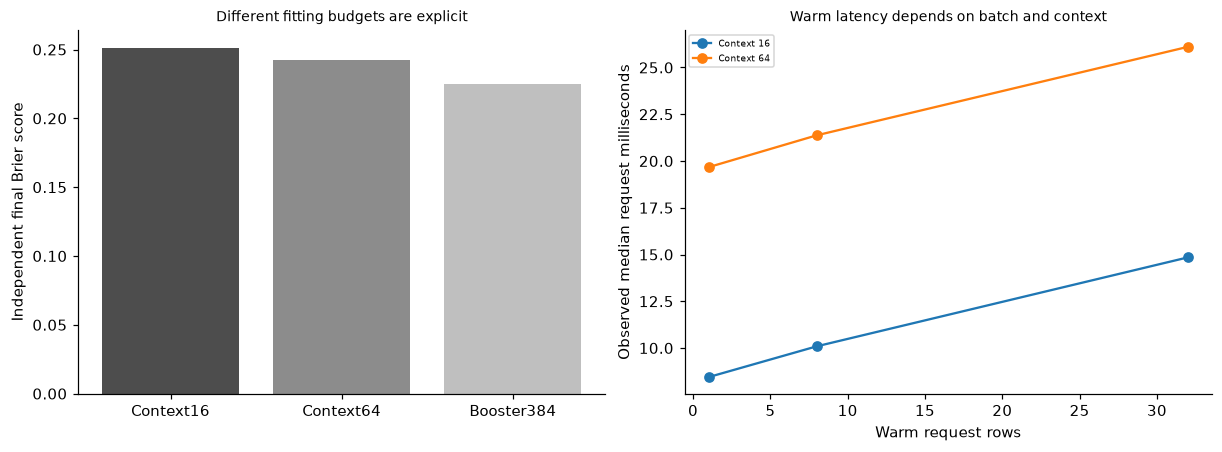

In [2]:
import os,hashlib,importlib.metadata,tracemalloc,concurrent.futures
from pathlib import Path
os.environ['HF_HUB_OFFLINE']='1'
from tabpfn import TabPFNClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neighbors import NearestNeighbors
VERSIONS['tabpfn']=importlib.metadata.version('tabpfn')
candidates=[Path.cwd(),Path.cwd().parent,Path.cwd()/'examples'];ROOT=next(p for p in candidates if (p/'examples.json').is_file());checkpoint=ROOT/'build/model-cache/models--Prior-Labs--TabPFN-v2-clf/snapshots/f851f2a3c941544733b712d8c0f96dfae9b28862/tabpfn-v2-classifier-v2_default.ckpt';assert checkpoint.is_file(),'First run python scripts/acquire_chapter35_model.py; see CHAPTER_41_ASSETS.md'
payload=checkpoint.read_bytes();assert len(payload)==29009539 and hashlib.sha256(payload).hexdigest()=='cf8c519c01eaf1613ee91239006d57b1c806ff5f23ac1aeb1315ba1015210e49';del payload
xs=rng.normal(size=(384,4));ys=rng.binomial(1,expit(.8*xs[:,0]-.5*xs[:,1]+.5*xs[:,2]*xs[:,3]));xf=rng.normal(size=(64,4));yf=rng.binomial(1,expit(.8*xf[:,0]-.5*xf[:,1]+.5*xf[:,2]*xf[:,3]));booster=HistGradientBoostingClassifier(max_iter=30,max_leaf_nodes=7,random_state=SEED).fit(xs,ys);bp=booster.predict_proba(xf)[:,1];contexts={size:np.r_[np.flatnonzero(ys==0)[:size//2],np.flatnonzero(ys==1)[:size//2]] for size in [16,64]};MEASUREMENTS={'context_profiles':[],'warm_batches':[]};scientific=[]
def digest_weights(m):return hashlib.sha256(b''.join(p.detach().cpu().numpy().tobytes() for module in m.models_ for p in module.parameters())).hexdigest()
for size,index in contexts.items():
    t=time.perf_counter();foundation=TabPFNClassifier(n_estimators=1,model_path=checkpoint,device='cpu',inference_precision=torch.float32,n_preprocessing_jobs=1,random_state=SEED);foundation.fit(xs[index],ys[index]);fit_seconds=time.perf_counter()-t;t=time.perf_counter();foundation.predict_proba(xf[:8]);initialization_seconds=time.perf_counter()-t;before=digest_weights(foundation);t=time.perf_counter();fp=foundation.predict_proba(xf)[:,1];first_seconds=time.perf_counter()-t;assert digest_weights(foundation)==before;assert np.all(np.isfinite(fp)) and np.all((fp>=0)&(fp<=1));scientific.append({'context_rows':size,'Brier':float(np.mean((fp-yf)**2)),'frozen_weights':True,'prediction_sha256':hashlib.sha256(fp.tobytes()).hexdigest()});MEASUREMENTS['context_profiles'].append({'context_rows':size,'construct_and_fit_seconds':fit_seconds,'initial_8_query_seconds':initialization_seconds,'post_initialization_64_query_seconds':first_seconds})
    for batchsize in [1,8,32]:
        foundation.predict_proba(xf[:batchsize]);durations=[]
        for _ in range(3):
            t=time.perf_counter();foundation.predict_proba(xf[:batchsize]);durations.append(time.perf_counter()-t)
        MEASUREMENTS['warm_batches'].append({'model':'TabPFN','context_rows':size,'batch_rows':batchsize,'median_seconds':float(np.median(durations)),'rows_per_second':batchsize/float(np.median(durations))})
assert len(scientific)==2;RESULTS.update(source_rows=384,final_rows=64,foundation_context_profiles=scientific,booster_Brier=float(np.mean((bp-yf)**2)),booster_training_rows=384,checkpoint_bytes=29009539,inference_precision='torch.float32',foundation_checkpoint='TabPFN-v2 classifier f851f2a',context_sizes_chosen_without_final_labels=True);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(['Context16','Context64','Booster384'],[r['Brier'] for r in scientific]+[RESULTS['booster_Brier']],color=['.3','.55','.75']);axes[0].set(ylabel='Independent final Brier score',title='Different fitting budgets are explicit');
for size in [16,64]:
    rows=[r for r in MEASUREMENTS['warm_batches'] if r['context_rows']==size];axes[1].plot([r['batch_rows'] for r in rows],[1000*r['median_seconds'] for r in rows],'o-',label=f'Context {size}')
axes[1].set(xlabel='Warm request rows',ylabel='Observed median request milliseconds',title='Warm latency depends on batch and context');axes[1].legend(fontsize=6);plt.show()


## Include retrieval, context refitting and serialization in an end-to-end request
 Retrieve32 nearest source records around each of four final query batches, using a fixed source-only index and no final responses. A new local context fit is part of every request; record retrieval, context-fit, prediction, serialization and total elapsed time separately. This is local process work, not network service latency. The final context model is also measured with tracemalloc, which observes Python allocations and excludes many native tensor buffers. Count native parameter and source-context array bytes separately; neither quantity is peak resident memory. Warm booster batch observations and an actual four-thread, eight-request booster-only workload illustrate throughput; no thread-safety claim is made about sharing a mutable foundation estimator. A hypothetical0.50 currency units per CPU-hour converts elapsed computation to a lower-bound compute scenario, not a quoted hosting price or complete operating bill.


,request,decode_seconds,retrieval_seconds,context_fit_seconds,model_seconds,serialization_seconds,end_to_end_seconds
0,0,0.000019,0.000364,0.037068,0.015147,0.000015,0.052613
1,1,0.000009,0.000315,0.008234,0.015219,0.000014,0.023792
2,2,0.000010,0.000301,0.008056,0.014966,0.000013,0.023346
3,3,0.000011,0.000341,0.008261,0.014550,0.000011,0.023174


,model,context_rows,batch_rows,median_seconds,rows_per_second
0,TabPFN,16,1,0.008443,118.440148
1,TabPFN,16,8,0.010091,792.788872
2,TabPFN,16,32,0.014846,2155.486853
3,TabPFN,64,1,0.019669,50.841749
4,TabPFN,64,8,0.021374,374.280685
5,TabPFN,64,32,0.026104,1225.852102
6,Histogram booster,384,1,0.000086,11656.231626
7,Histogram booster,384,8,0.000084,95238.095994
8,Histogram booster,384,32,0.000086,370297.574577


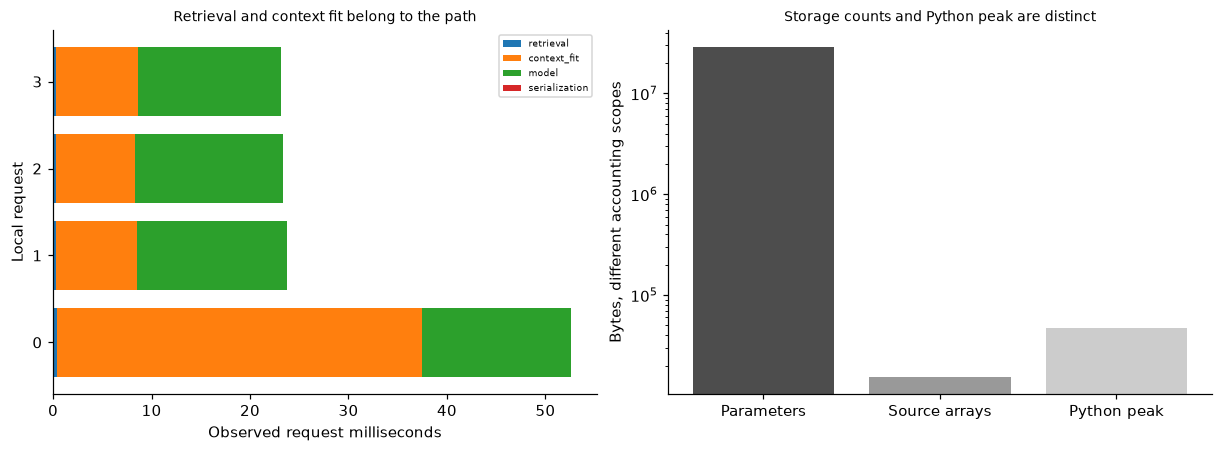

In [3]:
retriever=NearestNeighbors(n_neighbors=32).fit(xs);request_profiles=[];request_outputs=[]
for j in range(4):
    raw=json.dumps(xf[j*8:(j+1)*8].tolist());t0=time.perf_counter();query=np.array(json.loads(raw));t1=time.perf_counter();index=retriever.kneighbors(query.mean(0)[None],return_distance=False)[0];t2=time.perf_counter();foundation.fit(xs[index],ys[index]);t3=time.perf_counter();answer=foundation.predict_proba(query)[:,1];t4=time.perf_counter();response=json.dumps(answer.tolist());t5=time.perf_counter();assert len(json.loads(response))==8;request_outputs.extend(answer.tolist());request_profiles.append({'request':j,'decode_seconds':t1-t0,'retrieval_seconds':t2-t1,'context_fit_seconds':t3-t2,'model_seconds':t4-t3,'serialization_seconds':t5-t4,'end_to_end_seconds':t5-t0})
parameter_bytes=sum(p.numel()*p.element_size() for module in foundation.models_ for p in module.parameters());tracemalloc.start();foundation.predict_proba(xf[:8]);current,peak=tracemalloc.get_traced_memory();tracemalloc.stop();MEASUREMENTS.update(retrieval_requests=request_profiles,python_tracemalloc_prediction_peak_bytes=peak,native_parameter_bytes=parameter_bytes,source_pool_array_bytes=xs.nbytes+ys.nbytes)
for batchsize in [1,8,32]:
    booster.predict_proba(xf[:batchsize]);durations=[]
    for _ in range(5):
        t=time.perf_counter();booster.predict_proba(xf[:batchsize]);durations.append(time.perf_counter()-t)
    MEASUREMENTS['warm_batches'].append({'model':'Histogram booster','context_rows':384,'batch_rows':batchsize,'median_seconds':float(np.median(durations)),'rows_per_second':batchsize/float(np.median(durations))})
def booster_request(j):return booster.predict_proba(xf[(j%4)*16:(j%4+1)*16])[:,1]
t=time.perf_counter()
with concurrent.futures.ThreadPoolExecutor(max_workers=4) as executor:concurrent_answers=list(executor.map(booster_request,range(8)))
concurrent_seconds=time.perf_counter()-t;assert all(np.array_equal(v,bp[(j%4)*16:(j%4+1)*16]) for j,v in enumerate(concurrent_answers));MEASUREMENTS.update(booster_concurrent_requests=8,booster_concurrent_workers=4,booster_concurrent_seconds=concurrent_seconds,booster_concurrent_rows_per_second=128/concurrent_seconds,assumed_cpu_hour_rate=.5,mean_foundation_request_compute_cost=float(np.mean([r['end_to_end_seconds'] for r in request_profiles]))*.5/3600);RESULTS.update(actual_retrieval_requests=4,retrieved_context_rows=32,request_rows=8,retrieval_uses_final_labels=False,request_probability_sha256=hashlib.sha256(np.array(request_outputs).tobytes()).hexdigest(),native_parameter_bytes=parameter_bytes,source_pool_array_bytes=xs.nbytes+ys.nbytes,concurrent_booster_predictions_match_serial=True);display(pd.DataFrame(request_profiles));display(pd.DataFrame(MEASUREMENTS['warm_batches']));fig,axes=plt.subplots(1,2,figsize=(11,4));components=['retrieval_seconds','context_fit_seconds','model_seconds','serialization_seconds'];left=np.zeros(4)
for key in components:
    values=np.array([r[key]*1000 for r in request_profiles]);axes[0].barh(range(4),values,left=left,label=key.replace('_seconds',''));left+=values
axes[0].set(yticks=range(4),xlabel='Observed request milliseconds',ylabel='Local request',title='Retrieval and context fit belong to the path');axes[0].legend(fontsize=6);axes[1].bar(['Parameters','Source arrays','Python peak'],[parameter_bytes,xs.nbytes+ys.nbytes,peak],color=['.3','.6','.8']);axes[1].set(yscale='log',ylabel='Bytes, different accounting scopes',title='Storage counts and Python peak are distinct');plt.show()


In [4]:
summary={'example_id':'code_218','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual pinned TabPFN v2 checkpoint with verified SHA and frozen-parameter context fitting', 'source-only retrieval and end-to-end request timing including context fit serialization and inference', 'warm batch-size and context-size observations against compact histogram boosting', 'concurrent booster-only requests with explicit storage Python-heap and compute-cost boundaries'],'results':RESULTS,'resource_measurements':globals().get('MEASUREMENTS',{}),'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual pinned TabPFN v2 checkpoint with verified SHA and frozen-parameter context fitting", "source-only retrieval and end-to-end request timing including context fit serialization and inference", "warm batch-size and context-size observations against compact histogram boosting", "concurrent booster-only requests with explicit storage Python-heap and compute-cost boundaries"], "elapsed_seconds": 2.055, "example_id": "code_218", "hardware": "Darwin arm64 CPU", "resource_measurements": {"assumed_cpu_hour_rate": 0.5, "booster_concurrent_requests": 8, "booster_concurrent_rows_per_second": 59365.760244747406, "booster_concurrent_seconds": 0.00215612500323914, "booster_concurrent_workers": 4, "context_profiles": [{"construct_and_fit_seconds": 0.020879624993540347, "context_rows": 16, "initial_8_query_seconds": 0.024058333016000688, "post_initialization_64_query_seconds": 0.021433625021018088}, {"construct_and_fit_seconds": 0.0096002920181490